# Experiment 191 · Replay rate and timing

**Complete** · Controller evaluation saved · ETA 0h 00m 00s

The A–B–A–B stream, initial-A checkpoints, paired masks, MAE, optimizer and evaluation banks come from Experiment 190. Each arm performs one gradient update per arrival. Phase A varies the share of those updates allocated to historical images. Forgetting is previous-bank MSE minus its value at the switch. Adaptation is the drop in current-bank MSE since the switch. Phase A averages all 256-arrival readouts after the three switches.

Phase B forks fixed-25% checkpoints at each switch and at +3,072 arrivals. The schedules are fixed (25%, 25%), protect first (50%, 0%) and adapt first (0%, 50%). The primary endpoint is +512 arrivals with 128 replay updates per arm. At +256 the arms have spent different fractions of their shared budget. Both readouts are saved. Positive gains favor the candidate over fixed 25%.

The objective is current-bank MSE plus previous-bank forgetting above 0.005. Phase C requires a context-specific schedule chosen on fit-seed monitor banks to gain at least 0.005 there and on the held-out test-bank mean, with positive held-out gains in all three seeds and at least two switch positions. If it advances, the best constant rate is selected from Phase A on fit-seed monitor banks before the fresh-mask controller evaluation.

## A · Constant-rate frontier

| Rate | Completed trajectories |
| --- | --- |
 | 0% | 12 | 
 | 12.5% | 12 | 
 | 25% | 12 | 
 | 37.5% | 12 | 
 | 50% | 12 | 

| Rate | Matched pairs | Forgetting ↓ | Adaptation ↑ | Previous MSE ↓ | Current MSE ↓ | Objective ↓ |
| --- | --- | --- | --- | --- | --- | --- |
 | 0% | 12 | 0.33965 | 0.35006 | 1.24645 | 0.92261 | 1.25726 | 
 | 12.5% | 12 | -0.00466 | 0.14272 | 0.90231 | 0.91440 | 0.92803 | 
 | 25% | 12 | -0.03013 | 0.12786 | 0.87000 | 0.90297 | 0.90622 | 
 | 37.5% | 12 | -0.03569 | 0.13058 | 0.85776 | 0.89239 | 0.89357 | 
 | 50% | 12 | -0.03838 | 0.13526 | 0.85048 | 0.88293 | 0.88330 | 

| Switch | Rate | Forgetting ↓ | Adaptation ↑ |
| --- | --- | --- | --- |
 | A→B | 0% | +0.28787 | +0.40384 | 
 | A→B | 12.5% | -0.04271 | +0.40666 | 
 | A→B | 25% | -0.08254 | +0.40964 | 
 | A→B | 37.5% | -0.09614 | +0.41244 | 
 | A→B | 50% | -0.10389 | +0.41703 | 
 | B→A | 0% | +0.32086 | +0.32243 | 
 | B→A | 12.5% | +0.03310 | -0.02430 | 
 | B→A | 25% | +0.00954 | -0.02719 | 
 | B→A | 37.5% | +0.00017 | -0.01922 | 
 | B→A | 50% | -0.00337 | -0.01022 | 
 | A→B again | 0% | +0.41022 | +0.32390 | 
 | A→B again | 12.5% | -0.00438 | +0.04579 | 
 | A→B again | 25% | -0.01740 | +0.00113 | 
 | A→B again | 37.5% | -0.01110 | -0.00148 | 
 | A→B again | 50% | -0.00787 | -0.00103 | 

## B · Paired timing tests

72 sites measured.

| Context | Schedule | Held-out sites | Forgetting reduction | Adaptation gain | Objective gain |
| --- | --- | --- | --- | --- | --- |
 | switch | protect-first | 18 | -0.07087 | -0.03891 | -0.09334 | 
 | switch | adapt-first | 18 | +0.01736 | +0.01408 | +0.01891 | 
 | stable | protect-first | 18 | -0.01801 | -0.01016 | -0.02189 | 
 | stable | adapt-first | 18 | +0.00657 | +0.01568 | +0.01800 | 

Largest fixed-branch readout difference from Experiment 190 is 0 MSE.

**Phase C decision** · advance.

| Context | Fit-selected schedule | Fit gain | Held-out gain | Held-out seeds improved | Switch positions improved |
| --- | --- | --- | --- | --- | --- |
 | switch | adapt-first | +0.01685 | +0.01891 | 3/3 | 2/3 | 
 | stable | adapt-first | +0.01730 | +0.01800 | 3/3 | 3/3 | 

## C · Fresh-mask controller evaluation

Fit-selected best fixed rate is **50%**.

Held-out paired branch audit averages +0.01912 objective gain and 0.00142 oracle regret across 36 sites.

| Policy | Reference | Pairs | Forgetting reduction | Adaptation gain | Objective gain |
| --- | --- | --- | --- | --- | --- |
 | shift rule | 25% | 6 | -0.00691 | +0.00085 | -0.00429 | 
 | shift rule | 50% | 6 | -0.01393 | -0.00604 | -0.02457 | 
 | learned | 25% | 6 | -0.03504 | -0.00721 | -0.02762 | 
 | learned | 50% | 6 | -0.04205 | -0.01410 | -0.04791 | 

**Primary comparison** · Learned timing failed to improve the mean held-out objective against the fit-selected best fixed rate. It improved 0/3 held-out seeds.



In [ ]:
# Run this cell to watch the background worker. Interrupt it to stop watching.
from IPython.display import Image, Markdown, clear_output, display
from pathlib import Path
import base64, json, time

run = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-replay-schedule')
while True:
    try:
        status = json.loads((run / 'status.json').read_text(encoding='utf-8'))
        cells = json.loads((run / 'progress.ipynb').read_text(encoding='utf-8'))['cells']
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    for cell in cells:
        if cell['cell_type'] == 'markdown':
            display(Markdown(''.join(cell['source'])))
        for output in cell.get('outputs', []):
            if png := output.get('data', {}).get('image/png'):
                display(Image(data=base64.b64decode(png)))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)


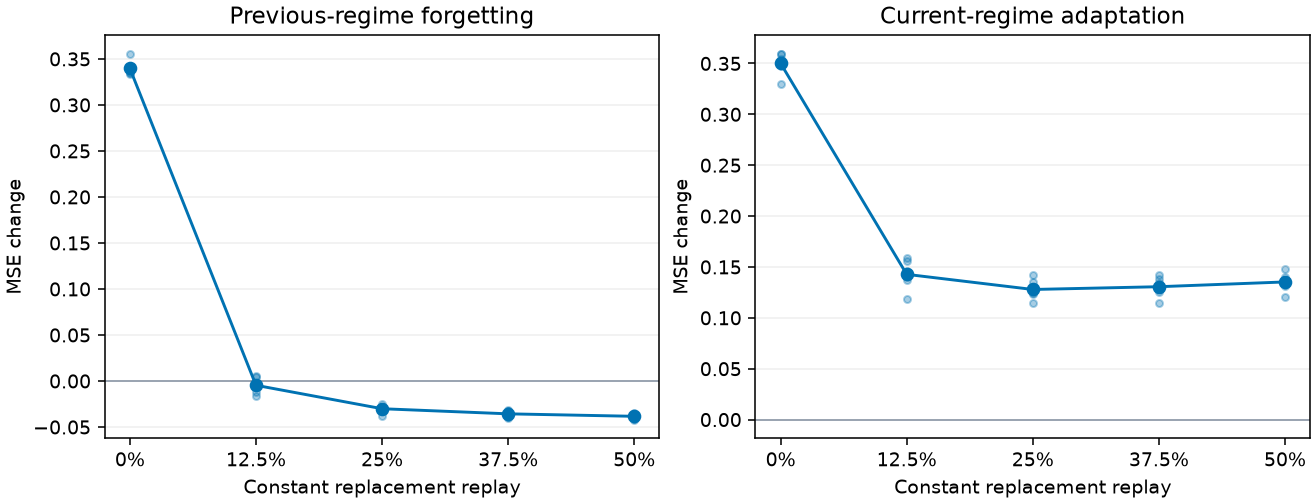